In [14]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import shutil
import random
from pathlib import Path
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import copy
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from PIL import Image  # Import PIL to resize images
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
import torch.optim as optim
from torch.optim import lr_scheduler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
#Setup Path
FILTERED_DIR = r"C:\Users\adria\Desktop\Msx Project\Coding\2nd dataset"  # Replace with actual dataset path
AUGMENTED_DIR = os.path.join(FILTERED_DIR, "augmented")
SPLITS = ["train", "val", "test"]
RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
BATCH_SIZE = 8
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


In [3]:
#Ensure necessary directories
for split in SPLITS:
    for label in ["PASS", "REJECT"]:
        os.makedirs(os.path.join(AUGMENTED_DIR, split, label), exist_ok=True)

In [7]:
#Ensure necessary directories
for split in SPLITS:
    for label in ["PASS", "REJECT"]:
        os.makedirs(os.path.join(AUGMENTED_DIR, split, label), exist_ok=True)

#Data Augmentation with New Transformations
transformations = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomPerspective(distortion_scale=0.5, p=0.5),
    transforms.Resize((224, 224))
])

for label in ["PASS", "REJECT"]:
    label_dir = os.path.join(FILTERED_DIR, label)
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    os.makedirs(augmented_label_dir, exist_ok=True)

    for image_name in os.listdir(label_dir):
        image_path = os.path.join(label_dir, image_name)
        image = Image.open(image_path).convert("RGB")

        for i in range(8):  # Augment to get 8x data
            augmented_image = transformations(image)
            augmented_image.save(os.path.join(augmented_label_dir, f"{Path(image_name).stem}_aug{i}.jpg"))

In [9]:
#Split Dataset
for label in ["PASS", "REJECT"]:
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    images = [os.path.join(augmented_label_dir, img) for img in os.listdir(augmented_label_dir)]

    train, test_val = train_test_split(images, test_size=(1 - RATIO["train"]))
    val, test = train_test_split(test_val, test_size=(RATIO["test"] / (RATIO["val"] + RATIO["test"])))

    for split, split_images in zip(SPLITS, [train, val, test]):
        split_dir = os.path.join(AUGMENTED_DIR, split, label)
        for img_path in split_images:
            shutil.copy(img_path, split_dir)

In [10]:
#Load Data and Label It
class CustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        for label, folder in enumerate(["PASS", "REJECT"]):
            folder_path = os.path.join(root_dir, folder)
            for img_name in os.listdir(folder_path):
                self.image_paths.append(os.path.join(folder_path, img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

#Prepare Data Loaders
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "train"), transform=transform)
val_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "val"), transform=transform)
test_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "test"), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [11]:
#Load and Fine-Tune ResNet101
Resnet101 = models.resnet101(pretrained=True)
print(Resnet101)
#Set requires_grad to True for all layers to match the script provided
for param in Resnet101.parameters():
    param.requires_grad = True

#Replace the final fully connected layer
num_features = Resnet101.fc.in_features
Resnet101.fc = nn.Linear(num_features, 2)  # 2 classes: PASS and REJECT
Resnet101 = Resnet101.to(DEVICE)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [30]:
#Define optimizer, loss function, and learning rate scheduler to match the provided script
optimizer = optim.Adam(Resnet101.parameters(), lr=0.00001)
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
loss_function = nn.CrossEntropyLoss()

#Training function
def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=50):
    metrics = {'train': [], 'val': []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch}/{num_epochs - 1}")
        print("-" * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            y_true, y_pred = [], []

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                y_true.extend(labels.cpu().numpy())
                y_pred.extend(preds.cpu().numpy())

            if phase == 'train':
                scheduler.step()

            # Calculate metrics
            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            accuracy = accuracy_score(y_true, y_pred)
            precision = precision_score(y_true, y_pred, average='weighted')
            recall = recall_score(y_true, y_pred, average='weighted')
            f1 = f1_score(y_true, y_pred, average='weighted')

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f}")
            print(f"Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")
            print()

            # Store metrics
            metrics[phase].append({
                'loss': epoch_loss,
                'accuracy': accuracy,
                'precision': precision,
                'recall': recall,
                'f1': f1
            })

    return model, metrics

In [31]:
#Test evaluation function
def evaluate_model(model, dataloader, device):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    
    #Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print("\nTest Phase Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}\n")

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [32]:
# Plotting function
def plot_metrics(metrics, test_metrics, num_epochs):
    epochs = range(num_epochs)

    # Plot Training Metrics
    train_losses = [m['loss'] for m in metrics['train']]
    train_accuracies = [m['accuracy'] for m in metrics['train']]
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.title('Training Metrics')
    plt.legend()
    plt.show()

    # Plot Validation Metrics
    val_losses = [m['loss'] for m in metrics['val']]
    val_accuracies = [m['accuracy'] for m in metrics['val']]
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.title('Validation Metrics')
    plt.legend()
    plt.show()

    # Plot Test Metrics
    plt.figure(figsize=(6, 5))
    plt.bar(['Test Accuracy'], [test_metrics['accuracy']], color='green')
    plt.title('Test Metrics')
    plt.ylabel('Accuracy')
    plt.show()

Using GPU for training.
Epoch 0/9
----------
Train Loss: 0.0130
Accuracy: 0.9966, Precision: 0.9966, Recall: 0.9966, F1: 0.9966

Val Loss: 0.2326
Accuracy: 0.9361, Precision: 0.9363, Recall: 0.9361, F1: 0.9361

Epoch 1/9
----------
Train Loss: 0.0131
Accuracy: 0.9961, Precision: 0.9961, Recall: 0.9961, F1: 0.9961

Val Loss: 0.2727
Accuracy: 0.9237, Precision: 0.9243, Recall: 0.9237, F1: 0.9237

Epoch 2/9
----------
Train Loss: 0.0113
Accuracy: 0.9964, Precision: 0.9964, Recall: 0.9964, F1: 0.9964

Val Loss: 0.2648
Accuracy: 0.9299, Precision: 0.9306, Recall: 0.9299, F1: 0.9299

Epoch 3/9
----------
Train Loss: 0.0198
Accuracy: 0.9948, Precision: 0.9948, Recall: 0.9948, F1: 0.9948

Val Loss: 0.2813
Accuracy: 0.9237, Precision: 0.9238, Recall: 0.9237, F1: 0.9237

Epoch 4/9
----------
Train Loss: 0.0158
Accuracy: 0.9951, Precision: 0.9951, Recall: 0.9951, F1: 0.9951

Val Loss: 0.4522
Accuracy: 0.9134, Precision: 0.9141, Recall: 0.9134, F1: 0.9134

Epoch 5/9
----------
Train Loss: 0.0195
A

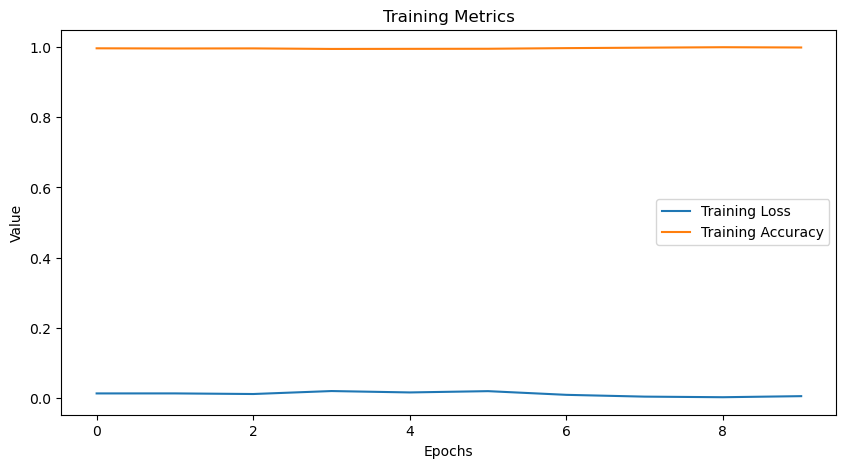

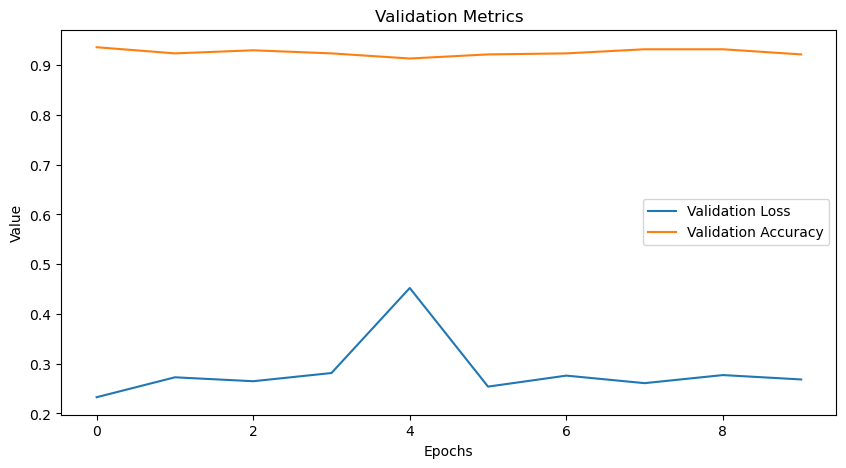

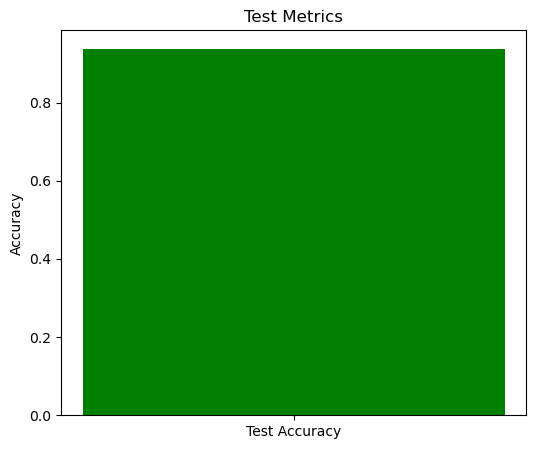

In [33]:
#Combine loaders into a dictionary
dataloaders = {
    'train': train_loader,
    'val': val_loader
}
#GPU Check
if DEVICE.type == 'cuda':
    print("Using GPU for training.")
else:
    print("Using CPU for training. Consider enabling CUDA for better performance.")
#Train the model
# Train the model
model, train_val_metrics = train_model(Resnet101, dataloaders, loss_function, optimizer, scheduler, num_epochs=10)

# Evaluate the model on the test dataset
test_metrics = evaluate_model(model, test_loader, DEVICE)

# Plot all metrics
plot_metrics(train_val_metrics, test_metrics, num_epochs=10)

In [22]:
# Save the trained model
torch.save(model.state_dict(), "resnet101_finetuned.pth")

In [ ]:
model_path = "resnet101_finetuned.pth"
model = Resnet101  
model.load_state_dict(torch.load(model_path))
model.eval()  #Set the model to evaluation mode

#Prepare the test dataloader
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),  #Match input size of ResNet
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
#test_dataset = YourDataset(test_data, transform=test_transforms)  #Replace with your dataset class
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Evaluation function
def evaluate_model(model, dataloader, device):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)

    return {
        'accuracy': accuracy
    }

    
test_metrics = evaluate_model(model, test_loader, DEVICE)

C:\Users\adria\AppData\Local\Temp\ipykernel_23584\2729170899.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))



Test Phase Metrics:
Accuracy: 0.9299
Precision: 0.9313
Recall: 0.9299
F1 Score: 0.9298


In [ ]:
# Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print("\nTest Phase Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [19]:
#Run evaluation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
accuracy, precision, recall, f1 = evaluate_model(model, test_loader, device)

#Display results
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Accuracy: 0.93
Precision: 0.93
Recall: 0.93
F1-Score: 0.93
